<a href="https://colab.research.google.com/github/grupobigdata2026/Big-Data-Deep-Learning---Tareas/blob/main/Tarea1_Spark_MLlib_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarea 1 – Spark MLlib Classification Pipeline

In this lab you will:
- Build a binary classification dataset
- Create a Spark ML pipeline
- Train a classifier and evaluate accuracy

_Nota (ES): Conectar con problemas de churn, fraude o riesgo de crédito._

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml import Pipeline

spark = SparkSession.builder.appName('MLlibLab').getOrCreate()

In [2]:
import pandas as pd
import numpy as np

n = 5000
pdf = pd.DataFrame({
    'feature_1': np.random.randn(n),
    'feature_2': np.random.randn(n),
    'feature_3': np.random.randn(n),
    'label': np.random.choice([0, 1], size=n, p=[0.7, 0.3])
})
csv_path = 'binary_classification_sample.csv'
pdf.to_csv(csv_path, index=False)

df = spark.read.csv(csv_path, header=True, inferSchema=True)
df.show(5)

+--------------------+--------------------+-------------------+-----+
|           feature_1|           feature_2|          feature_3|label|
+--------------------+--------------------+-------------------+-----+
|  1.1243679661812536| -0.3819334570137161| 1.3691889524083525|    0|
| 0.07190444344095824|  1.0061292136284745|-0.6611549407144282|    1|
|-0.01362011805402...|  0.8104692976498399|-1.1499182952876685|    0|
|  0.3967951462844759|-0.09545268132611179|-0.9755108348554551|    0|
| -0.7128502245412558|  1.0024935960864014| 1.3823558963889295|    0|
+--------------------+--------------------+-------------------+-----+
only showing top 5 rows


## 1. Build a Pipeline

We will assemble features and train a logistic regression model.

In [3]:
feature_cols = ['feature_1', 'feature_2', 'feature_3']
assembler = VectorAssembler(inputCols=feature_cols, outputCol='features')

lr = LogisticRegression(featuresCol='features', labelCol='label')
pipeline = Pipeline(stages=[assembler, lr])

train, test = df.randomSplit([0.8, 0.2], seed=42)
model = pipeline.fit(train)

predictions = model.transform(test)
predictions.select('features', 'label', 'probability', 'prediction').show(10)

+--------------------+-----+--------------------+----------+
|            features|label|         probability|prediction|
+--------------------+-----+--------------------+----------+
|[-3.3257073735930...|    0|[0.70115106023713...|       0.0|
|[-3.0624448358806...|    1|[0.69363163700206...|       0.0|
|[-2.9079401952308...|    0|[0.68618600477819...|       0.0|
|[-2.6993925879127...|    0|[0.69552856276317...|       0.0|
|[-2.5528570416435...|    0|[0.70101533444186...|       0.0|
|[-2.4553282936624...|    0|[0.70231958152469...|       0.0|
|[-2.3936132611237...|    0|[0.70373370365493...|       0.0|
|[-2.3443308434655...|    0|[0.70182041118734...|       0.0|
|[-2.2614974563795...|    1|[0.70191608195062...|       0.0|
|[-2.2579154499559...|    0|[0.69634721832010...|       0.0|
+--------------------+-----+--------------------+----------+
only showing top 10 rows


In [4]:
from pyspark.ml.classification import LinearSVC

# Create a Linear Support Vector Machine (SVM) model
svm = LinearSVC(featuresCol='features', labelCol='label', maxIter=10)

# Create a new pipeline with the SVM model
pipeline_svm = Pipeline(stages=[assembler, svm])

# Fit the pipeline to the training data
model_svm = pipeline_svm.fit(train)

# Make predictions on the test data
predictions_svm = model_svm.transform(test)
predictions_svm.select('features', 'label', 'rawPrediction', 'prediction').show(10)

+--------------------+-----+--------------------+----------+
|            features|label|       rawPrediction|prediction|
+--------------------+-----+--------------------+----------+
|[-3.3257073735930...|    0|[1.00002567621786...|       0.0|
|[-3.0624448358806...|    1|[0.99996860879284...|       0.0|
|[-2.9079401952308...|    0|[1.00000232198729...|       0.0|
|[-2.6993925879127...|    0|[1.00003268778489...|       0.0|
|[-2.5528570416435...|    0|[1.00001798868649...|       0.0|
|[-2.4553282936624...|    0|[1.00002804592419...|       0.0|
|[-2.3936132611237...|    0|[0.99998760334664...|       0.0|
|[-2.3443308434655...|    0|[0.99998327163388...|       0.0|
|[-2.2614974563795...|    1|[1.00000676746735...|       0.0|
|[-2.2579154499559...|    0|[0.99998621997366...|       0.0|
+--------------------+-----+--------------------+----------+
only showing top 10 rows


In [5]:
from pyspark.ml.classification import RandomForestClassifier

# Create a Random Forest classifier model
rf = RandomForestClassifier(featuresCol='features', labelCol='label', numTrees=10)

# Create a new pipeline with the Random Forest model
pipeline_rf = Pipeline(stages=[assembler, rf])

# Fit the pipeline to the training data
model_rf = pipeline_rf.fit(train)

# Make predictions on the test data
predictions_rf = model_rf.transform(test)
predictions_rf.select('features', 'label', 'rawPrediction', 'prediction').show(10)

+--------------------+-----+--------------------+----------+
|            features|label|       rawPrediction|prediction|
+--------------------+-----+--------------------+----------+
|[-3.3257073735930...|    0|[6.54335427070596...|       0.0|
|[-3.0624448358806...|    1|[6.91907690270347...|       0.0|
|[-2.9079401952308...|    0|[6.63950254668101...|       0.0|
|[-2.6993925879127...|    0|[7.23260868927418...|       0.0|
|[-2.5528570416435...|    0|[7.09472335382327...|       0.0|
|[-2.4553282936624...|    0|[7.26904389398730...|       0.0|
|[-2.3936132611237...|    0|[7.17316297940857...|       0.0|
|[-2.3443308434655...|    0|[7.17316297940857...|       0.0|
|[-2.2614974563795...|    1|[7.17316297940857...|       0.0|
|[-2.2579154499559...|    0|[7.14212675736288...|       0.0|
+--------------------+-----+--------------------+----------+
only showing top 10 rows


In [6]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Evaluate Logistic Regression model accuracy
evaluator = MulticlassClassificationEvaluator(labelCol='label', predictionCol='prediction', metricName='accuracy')
accuracy_lr = evaluator.evaluate(predictions)
print(f"Logistic Regression Model Accuracy: {accuracy_lr:.4f}")

Logistic Regression Model Accuracy: 0.7140


In [7]:
# Evaluate SVM model accuracy
accuracy_svm = evaluator.evaluate(predictions_svm)
print(f"SVM Model Accuracy: {accuracy_svm:.4f}")

SVM Model Accuracy: 0.7140


In [8]:
# Evaluate Random Forest model accuracy
accuracy_rf = evaluator.evaluate(predictions_rf)
print(f"Random Forest Model Accuracy: {accuracy_rf:.4f}")

Random Forest Model Accuracy: 0.7140



--- Logistic Regression Model ---


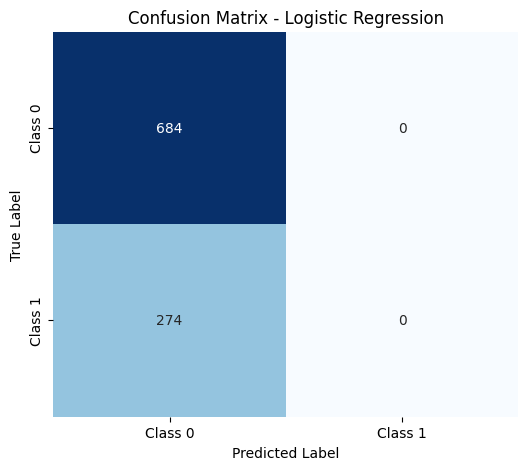

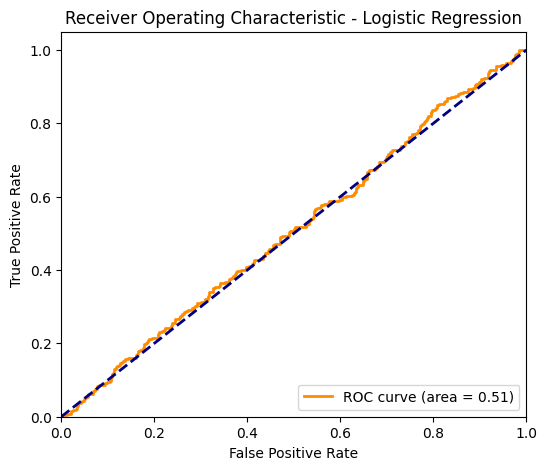


--- SVM Model ---


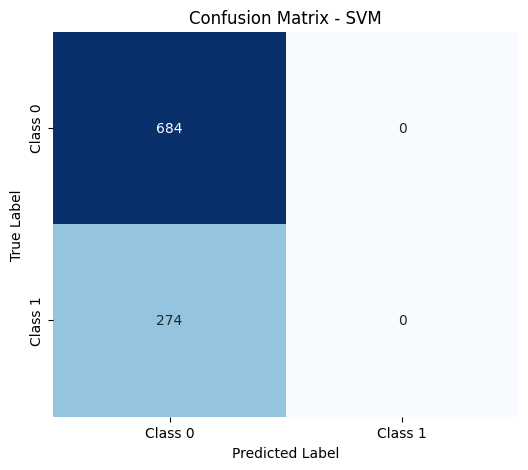

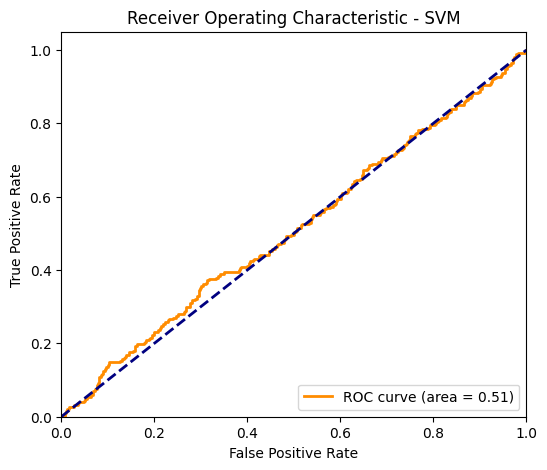


--- Random Forest Model ---


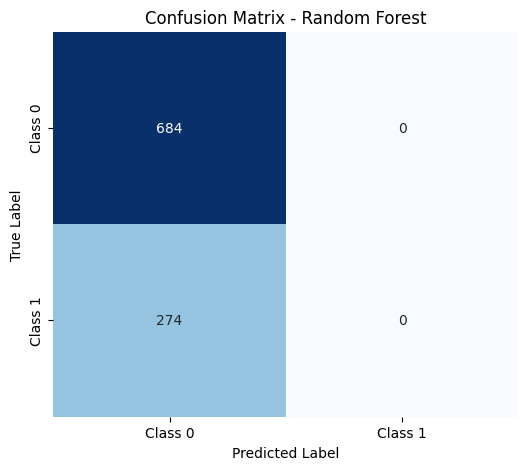

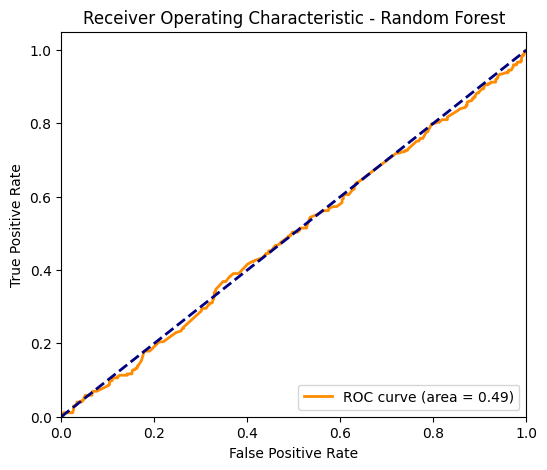


Note: Generating traditional learning curves (model performance vs. training set size) is computationally intensive in PySpark MLlib as it would require re-fitting the models multiple times with different subsets of the training data. Therefore, they are not included in this output.


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc

# Helper function to plot Confusion Matrix
def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title(f'Confusion Matrix - {title}')
    plt.show()

# Helper function to plot ROC Curve
def plot_roc_curve(y_true, y_scores, title):
    fpr, tpr, _ = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'Receiver Operating Characteristic - {title}')
    plt.legend(loc='lower right')
    plt.show()


# --- Logistic Regression --- #
print("\n--- Logistic Regression Model ---")
predictions_lr_pd = predictions.select('label', 'prediction', 'probability').toPandas()

# Confusion Matrix
plot_confusion_matrix(predictions_lr_pd['label'], predictions_lr_pd['prediction'], 'Logistic Regression')

# ROC Curve
# 'probability' column is a vector; we need the probability of the positive class (index 1)
prob_lr_positive = predictions_lr_pd['probability'].apply(lambda x: x[1])
plot_roc_curve(predictions_lr_pd['label'], prob_lr_positive, 'Logistic Regression')


# --- SVM --- #
print("\n--- SVM Model ---")
predictions_svm_pd = predictions_svm.select('label', 'prediction', 'rawPrediction').toPandas()

# Confusion Matrix
plot_confusion_matrix(predictions_svm_pd['label'], predictions_svm_pd['prediction'], 'SVM')

# ROC Curve
# 'rawPrediction' for LinearSVC is a vector of scores. We use the score for the positive class (index 1).
# LinearSVC does not directly provide probabilities; raw prediction scores are used as decision function scores.
score_svm_positive = predictions_svm_pd['rawPrediction'].apply(lambda x: x[1])
plot_roc_curve(predictions_svm_pd['label'], score_svm_positive, 'SVM')


# --- Random Forest --- #
print("\n--- Random Forest Model ---")
predictions_rf_pd = predictions_rf.select('label', 'prediction', 'probability').toPandas()

# Confusion Matrix
plot_confusion_matrix(predictions_rf_pd['label'], predictions_rf_pd['prediction'], 'Random Forest')

# ROC Curve
# 'probability' column is a vector; we need the probability of the positive class (index 1)
prob_rf_positive = predictions_rf_pd['probability'].apply(lambda x: x[1])
plot_roc_curve(predictions_rf_pd['label'], prob_rf_positive, 'Random Forest')


print("\nNote: Generating traditional learning curves (model performance vs. training set size) is computationally intensive in PySpark MLlib as it would require re-fitting the models multiple times with different subsets of the training data. Therefore, they are not included in this output.")

In [10]:
from pyspark.ml.classification import DecisionTreeClassifier

# Create a Decision Tree Classifier model
dt = DecisionTreeClassifier(featuresCol='features', labelCol='label')

# Create a new pipeline with the Decision Tree model
pipeline_dt = Pipeline(stages=[assembler, dt])

# Fit the pipeline to the training data
model_dt = pipeline_dt.fit(train)

# Make predictions on the test data
predictions_dt = model_dt.transform(test)
predictions_dt.select('features', 'label', 'rawPrediction', 'prediction').show(10)

# Evaluate Decision Tree model accuracy
accuracy_dt = evaluator.evaluate(predictions_dt)
print(f"\nDecision Tree Model Accuracy: {accuracy_dt:.4f}")

+--------------------+-----+--------------+----------+
|            features|label| rawPrediction|prediction|
+--------------------+-----+--------------+----------+
|[-3.3257073735930...|    0|[2004.0,901.0]|       0.0|
|[-3.0624448358806...|    1|[2004.0,901.0]|       0.0|
|[-2.9079401952308...|    0|[2004.0,901.0]|       0.0|
|[-2.6993925879127...|    0| [697.0,248.0]|       0.0|
|[-2.5528570416435...|    0|[2004.0,901.0]|       0.0|
|[-2.4553282936624...|    0| [697.0,248.0]|       0.0|
|[-2.3936132611237...|    0|[2004.0,901.0]|       0.0|
|[-2.3443308434655...|    0|[2004.0,901.0]|       0.0|
|[-2.2614974563795...|    1|[2004.0,901.0]|       0.0|
|[-2.2579154499559...|    0|[2004.0,901.0]|       0.0|
+--------------------+-----+--------------+----------+
only showing top 10 rows

Decision Tree Model Accuracy: 0.7067


# Tarea 1

Hacer los sguientes cambios y hacer el análisis respectivo.

In [11]:

# import numpy as np
# import pandas as pd
#
# n = 5000
# pdf_improved = pd.DataFrame({
#     'feature_1': np.random.randn(n),
#     'feature_2': np.random.randn(n),
#     'feature_3': np.random.randn(n)
# })
# # Create a label that depends on the features, for example:
# pdf_improved['label'] = ((pdf_improved['feature_1'] + 2*pdf_improved['feature_2'] - 0.5*pdf_improved['feature_3']) > 0).astype(int)
# # You can also add some noise to make it more realistic
# noise = np.random.rand(n) < 0.1 # 10% of labels are flipped randomly
# pdf_improved.loc[noise, 'label'] = 1 - pdf_improved.loc[noise, 'label']
#
# # Then save this new dataset and use it for training:
# csv_path_improved = 'improved_binary_classification_sample.csv'
# pdf_improved.to_csv(csv_path_improved, index=False)
# df_improved = spark.read.csv(csv_path_improved, header=True, inferSchema=True)
# train_improved, test_improved = df_improved.randomSplit([0.8, 0.2], seed=42)
#
# # And re-run your pipelines with train_improved and test_improved


Modelo                           | Accuracy | AUC-ROC  | F1-Score | Precision | Recall  
-------------------------------------------------------------------------------------
Logistic Regression (Improved)   | 0.8914   | 0.8958   | 0.8915   | 0.8920    | 0.8914  
Linear SVM (Improved)            | 0.8956   | 0.8957   | 0.8956   | 0.8959    | 0.8956  
Random Forest (Improved)         | 0.8622   | 0.8909   | 0.8622   | 0.8643    | 0.8622  


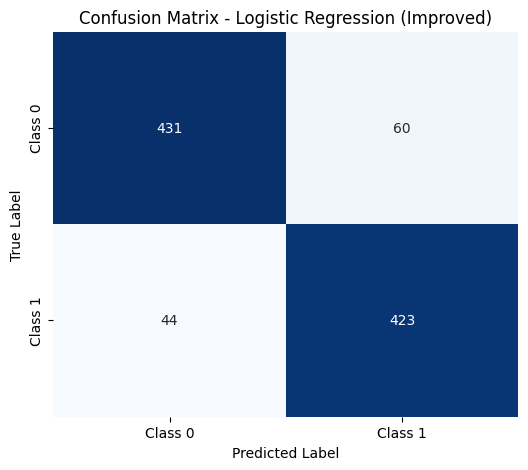

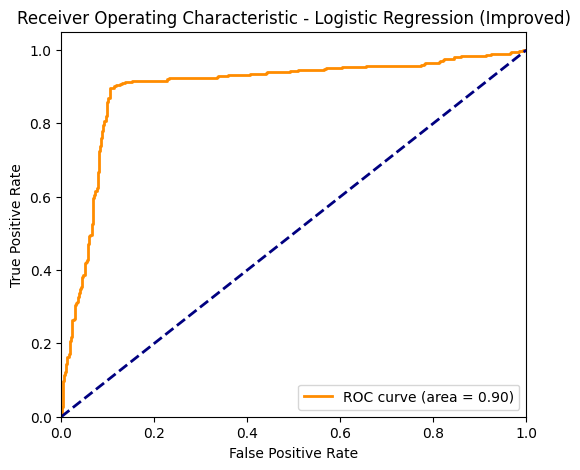

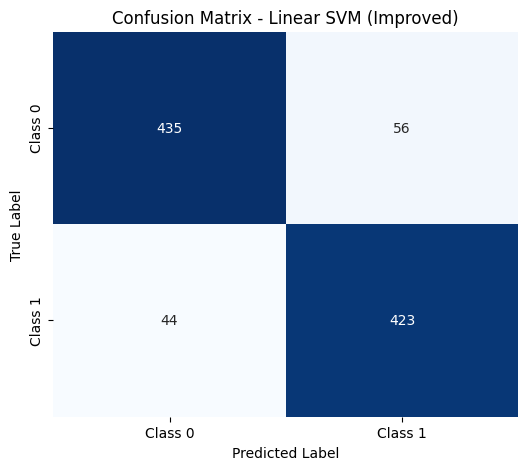

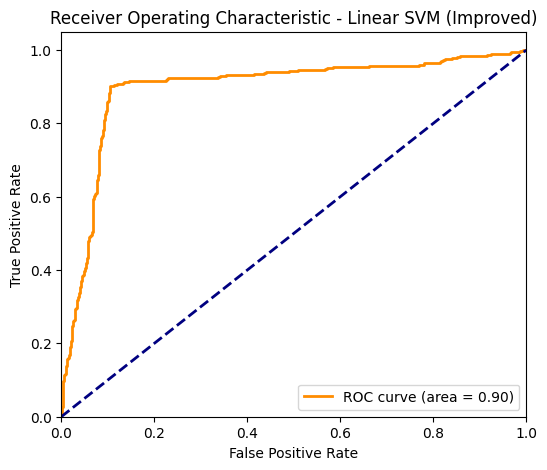

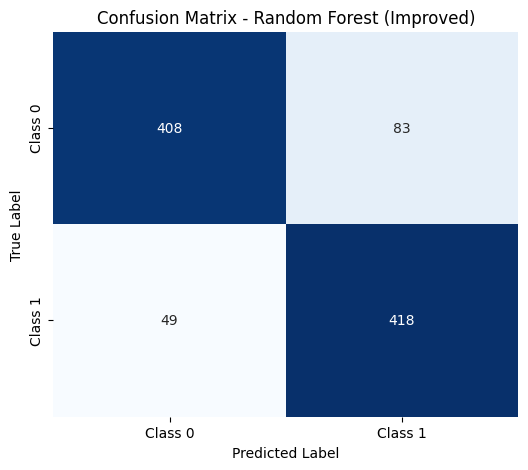

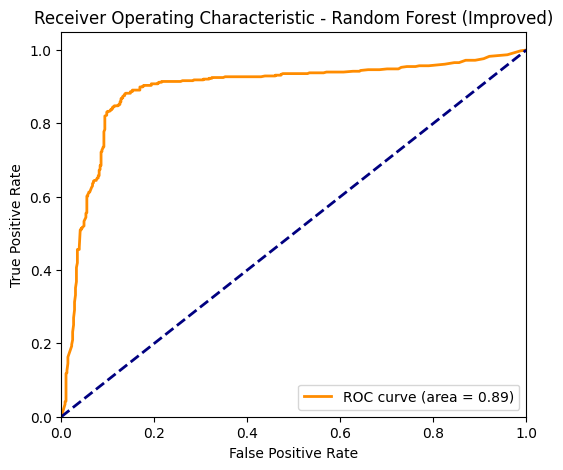

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator

# 1. Crear el dataset mejorado donde 'label' depende de las features
np.random.seed(42)  # Para reproducibilidad
n = 5000
pdf_improved = pd.DataFrame({
    'feature_1': np.random.randn(n),
    'feature_2': np.random.randn(n),
    'feature_3': np.random.randn(n)
})

# Relación lineal real entre features y etiqueta
pdf_improved['label'] = ((pdf_improved['feature_1'] + 2*pdf_improved['feature_2'] - 0.5*pdf_improved['feature_3']) > 0).astype(int)

# Agregar 10% de ruido aleatorio para hacerlo más realista
noise = np.random.rand(n) < 0.1
pdf_improved.loc[noise, 'label'] = 1 - pdf_improved.loc[noise, 'label']

# Guardar y cargar en PySpark
csv_path_improved = 'improved_binary_classification_sample.csv'
pdf_improved.to_csv(csv_path_improved, index=False)
df_improved = spark.read.csv(csv_path_improved, header=True, inferSchema=True)

# Split 80/20
train_improved, test_improved = df_improved.randomSplit([0.8, 0.2], seed=42)

# 2. Re-entrenar los 3 pipelines existentes con train_improved y predecir en test_improved
model_lr_imp = pipeline.fit(train_improved)
predictions_lr_imp = model_lr_imp.transform(test_improved)

model_svm_imp = pipeline_svm.fit(train_improved)
predictions_svm_imp = model_svm_imp.transform(test_improved)

model_rf_imp = pipeline_rf.fit(train_improved)
predictions_rf_imp = model_rf_imp.transform(test_improved)

# 3. Evaluación comparativa de métricas (Accuracy, AUC-ROC, F1, Precision, Recall)
acc_eval = MulticlassClassificationEvaluator(labelCol='label', predictionCol='prediction', metricName='accuracy')
auc_eval = BinaryClassificationEvaluator(labelCol='label', rawPredictionCol='rawPrediction', metricName='areaUnderROC')
f1_eval = MulticlassClassificationEvaluator(labelCol='label', predictionCol='prediction', metricName='f1')
prec_eval = MulticlassClassificationEvaluator(labelCol='label', predictionCol='prediction', metricName='weightedPrecision')
rec_eval = MulticlassClassificationEvaluator(labelCol='label', predictionCol='prediction', metricName='weightedRecall')

modelos_imp = [
    ("Logistic Regression (Improved)", predictions_lr_imp),
    ("Linear SVM (Improved)", predictions_svm_imp),
    ("Random Forest (Improved)", predictions_rf_imp)
]

print(f"{'Modelo':<32} | {'Accuracy':<8} | {'AUC-ROC':<8} | {'F1-Score':<8} | {'Precision':<9} | {'Recall':<8}")
print("-" * 85)
for nombre, pred in modelos_imp:
    print(f"{nombre:<32} | {acc_eval.evaluate(pred):<8.4f} | {auc_eval.evaluate(pred):<8.4f} | "
          f"{f1_eval.evaluate(pred):<8.4f} | {prec_eval.evaluate(pred):<9.4f} | {rec_eval.evaluate(pred):<8.4f}")

# 4. Graficar Matrices de Confusión y Curvas ROC para los modelos mejorados
# --- Logistic Regression ---
pred_lr_imp_pd = predictions_lr_imp.select('label', 'prediction', 'probability').toPandas()
plot_confusion_matrix(pred_lr_imp_pd['label'], pred_lr_imp_pd['prediction'], 'Logistic Regression (Improved)')
plot_roc_curve(pred_lr_imp_pd['label'], pred_lr_imp_pd['probability'].apply(lambda x: x[1]), 'Logistic Regression (Improved)')

# --- Linear SVM ---
pred_svm_imp_pd = predictions_svm_imp.select('label', 'prediction', 'rawPrediction').toPandas()
plot_confusion_matrix(pred_svm_imp_pd['label'], pred_svm_imp_pd['prediction'], 'Linear SVM (Improved)')
plot_roc_curve(pred_svm_imp_pd['label'], pred_svm_imp_pd['rawPrediction'].apply(lambda x: x[1]), 'Linear SVM (Improved)')

# --- Random Forest ---
pred_rf_imp_pd = predictions_rf_imp.select('label', 'prediction', 'probability').toPandas()
plot_confusion_matrix(pred_rf_imp_pd['label'], pred_rf_imp_pd['prediction'], 'Random Forest (Improved)')
plot_roc_curve(pred_rf_imp_pd['label'], pred_rf_imp_pd['probability'].apply(lambda x: x[1]), 'Random Forest (Improved)')